# 04 · ratio、Clip 与 Critic loss

## 学习目标

观察正负优势下的 clipped surrogate，并确认 target detach 后的梯度流。

默认运行参考实现。练习 Cell 需要主动启用，修改 `.py` 后重新运行。

## 环境准备

先按 [使用指南](README.md) 安装 `.[dev,notebook]`，选择项目 Kernel。

In [1]:
from pathlib import Path
import os
import sys
import torch
import numpy as np

# 从仓库根目录或 notebooks/ 打开都可；不要依赖某台机器的绝对路径。
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'pyproject.toml').exists()
                     and (p / 'src/ppo_pendulum').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('请从项目目录启动 JupyterLab')
os.chdir(PROJECT_ROOT)
%load_ext autoreload
%autoreload 2
torch.manual_seed(7)
np.random.seed(7)
print('Python:', sys.executable)
print('Project:', PROJECT_ROOT.name)

Python: /Users/matt/Documents/Codex/2026-11-15/referenced-chatgpt-conversation-this-is-an-2/work/.venv/bin/python
Project: ppo-inverted-pendulum


## 1. 用 ratio 直接检查 Clip

正优势、ratio=1.5 时，收益上限为 1.2；负优势时保留 -1.5 的惩罚。

In [2]:
from ppo_pendulum.reference.algorithm import ppo_clipped_actor_loss, value_loss
ratio_input = torch.tensor([1.5, 1.5])
advantages = torch.tensor([1., -1.])
actor_loss, ratios, clip_fraction = ppo_clipped_actor_loss(
    ratio_input.log(), torch.zeros(2), advantages, 0.2)
print('ratio:', ratios, 'loss:', actor_loss.item(), 'clip fraction:', clip_fraction.item())
torch.testing.assert_close(actor_loss, torch.tensor(0.15))

ratio: tensor([1.5000, 1.5000]) loss: 0.1499999761581421 clip fraction: 1.0


## 2. 画出每条样本的代理目标

图上是最大化的 surrogate；代码交给优化器的是它的负值。横轴只展示人工构造的 ratio，不是训练历史。

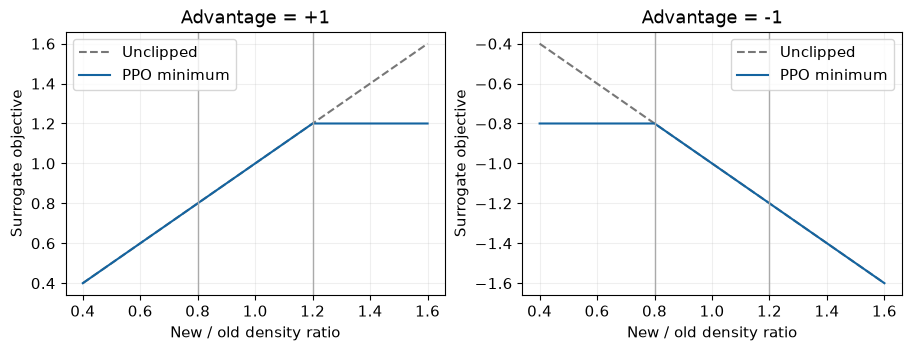

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (8, 3.4), 'font.size': 11})
ratio_grid = torch.linspace(0.4, 1.6, 121)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
for ax, advantage in zip(axes, [1., -1.]):
    raw = ratio_grid * advantage
    clipped = torch.minimum(raw, ratio_grid.clamp(0.8, 1.2) * advantage)
    ax.plot(ratio_grid, raw, '--', label='Unclipped', color='#777777')
    ax.plot(ratio_grid, clipped, label='PPO minimum', color='#1464a0')
    ax.axvline(0.8, color='#aaaaaa', linewidth=1)
    ax.axvline(1.2, color='#aaaaaa', linewidth=1)
    ax.set(title=f'Advantage = {advantage:+.0f}', xlabel='New / old density ratio', ylabel='Surrogate objective')
    ax.grid(alpha=0.2)
    ax.legend()
plt.show()

## 3. Critic target 必须固定

先显式 detach target，再调用 value loss；预测值需要梯度，监督标签不需要梯度。

In [4]:
predicted_values = torch.tensor([1., 3.], requires_grad=True)
target_source = torch.tensor([2., 1.], requires_grad=True)
critic_loss = value_loss(predicted_values, target_source.detach())
critic_loss.backward()
print('value loss:', critic_loss.item(), 'prediction gradient:', predicted_values.grad)
torch.testing.assert_close(predicted_values.grad, torch.tensor([-0.5, 1.]))
assert target_source.grad is None

value loss: 1.25 prediction gradient: tensor([-0.5000,  1.0000])


## 4. 手写 TODO 与检查

编辑 `src/ppo_pendulum/exercises/losses.py`。练习版 value loss 要在内部 detach target，配合检查器验证。

In [5]:
RUN_EXERCISE = False
if RUN_EXERCISE:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pytest', '-q',
                    'checks/test_exercises.py', '-k', 'stage_4'], check=True)
else:
    print('完成 losses.py 后启用练习检查。')

完成 losses.py 后启用练习检查。


## 下一步

打开 `05_rollout_debugging.ipynb`，检查真实环境采样后的 batch。

公式对照：[PPO_FORMULAS.md](../docs/PPO_FORMULAS.md)。